# Data Cleaning & Preprocessing

## Objective

To identify and handle missing values, duplicate
records, incorrect data types and outliers.

The objective is to prepare reliable data for
exploratory analysis and machine learning.

In [3]:
# Importing libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading original datasets

train_df = pd.read_csv("../data/raw/train.csv")
test_df = pd.read_csv("../data/raw/test.csv")

# Creating working copies

train_clean = train_df.copy()
test_clean = test_df.copy()

print("Working datasets created successfully!")

Working datasets created successfully!


In [4]:
# Missing values in training dataset

train_missing = pd.DataFrame({
    "Missing_Count": train_clean.isnull().sum(),
    "Missing_Percentage": (
        train_clean.isnull().sum() / len(train_clean)
    ) * 100
})

train_missing = train_missing[
    train_missing["Missing_Count"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

train_missing

,Missing_Count,Missing_Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


In [5]:
# Missing values in testing dataset

test_missing = pd.DataFrame({
    "Missing_Count": test_clean.isnull().sum(),
    "Missing_Percentage": (
        test_clean.isnull().sum() / len(test_clean)
    ) * 100
})

test_missing = test_missing[
    test_missing["Missing_Count"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

test_missing

,Missing_Count,Missing_Percentage
PoolQC,1456,99.794380
MiscFeature,1408,96.504455
Alley,1352,92.666210
Fence,1169,80.123372
MasVnrType,894,61.274846
FireplaceQu,730,50.034270
LotFrontage,227,15.558602
GarageQual,78,5.346127
GarageCond,78,5.346127
GarageYrBlt,78,5.346127


In [6]:
# Categorical columns where NA means feature does not exist

none_columns = [
    "Alley",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "PoolQC",
    "Fence",
    "MiscFeature"
]

In [7]:
# Filling structural missing values

for col in none_columns:

    train_clean[col] = train_clean[col].fillna("None")

    test_clean[col] = test_clean[col].fillna("None")

print("Categorical structural missing values handled.")

Categorical structural missing values handled.


In [8]:
# Numerical columns where missing indicates absence

zero_columns = [
    "MasVnrArea",
    "GarageYrBlt",
    "GarageArea",
    "GarageCars",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "BsmtFullBath",
    "BsmtHalfBath"
]

In [9]:
# Filling structural numerical missing values

for col in zero_columns:

    train_clean[col] = train_clean[col].fillna(0)

    test_clean[col] = test_clean[col].fillna(0)

print("Numerical structural missing values handled.")

Numerical structural missing values handled.


In [10]:
# Handling missing Masonry Veneer Type

train_clean["MasVnrType"] = train_clean["MasVnrType"].fillna("None")

test_clean["MasVnrType"] = test_clean["MasVnrType"].fillna("None")

In [11]:
# Calculating neighborhood-wise median

neighborhood_median = train_clean.groupby(
    "Neighborhood"
)["LotFrontage"].median()

print(neighborhood_median)

Neighborhood
Blmngtn    43.0
Blueste    24.0
BrDale     21.0
BrkSide    52.0
ClearCr    80.0
CollgCr    70.0
Crawfor    74.0
Edwards    65.5
Gilbert    65.0
IDOTRR     60.0
MeadowV    21.0
Mitchel    73.0
NAmes      73.0
NPkVill    24.0
NWAmes     80.0
NoRidge    91.0
NridgHt    88.5
OldTown    60.0
SWISU      60.0
Sawyer     71.0
SawyerW    66.5
Somerst    73.5
StoneBr    61.5
Timber     85.0
Veenker    68.0
Name: LotFrontage, dtype: float64


In [12]:
# Filling LotFrontage using neighborhood median

train_clean["LotFrontage"] = train_clean[
    "LotFrontage"
].fillna(
    train_clean["Neighborhood"].map(neighborhood_median)
)

test_clean["LotFrontage"] = test_clean[
    "LotFrontage"
].fillna(
    test_clean["Neighborhood"].map(neighborhood_median)
)

In [13]:
# Calculating neighborhood-wise median

neighborhood_median = train_clean.groupby(
    "Neighborhood"
)["LotFrontage"].median()

print(neighborhood_median)

Neighborhood
Blmngtn    43.0
Blueste    24.0
BrDale     21.0
BrkSide    52.0
ClearCr    80.0
CollgCr    70.0
Crawfor    74.0
Edwards    65.5
Gilbert    65.0
IDOTRR     60.0
MeadowV    21.0
Mitchel    73.0
NAmes      73.0
NPkVill    24.0
NWAmes     80.0
NoRidge    91.0
NridgHt    88.5
OldTown    60.0
SWISU      60.0
Sawyer     71.0
SawyerW    66.5
Somerst    73.5
StoneBr    61.5
Timber     85.0
Veenker    68.0
Name: LotFrontage, dtype: float64


In [14]:
# Filling LotFrontage using neighborhood median

train_clean["LotFrontage"] = train_clean[
    "LotFrontage"
].fillna(
    train_clean["Neighborhood"].map(neighborhood_median)
)

test_clean["LotFrontage"] = test_clean[
    "LotFrontage"
].fillna(
    test_clean["Neighborhood"].map(neighborhood_median)
)

In [15]:
# Global training median as fallback

global_median = train_df["LotFrontage"].median()

train_clean["LotFrontage"] = train_clean[
    "LotFrontage"
].fillna(global_median)

test_clean["LotFrontage"] = test_clean[
    "LotFrontage"
].fillna(global_median)

In [16]:
# Finding mode of Electrical

electrical_mode = train_clean["Electrical"].mode()[0]

print("Electrical Mode:", electrical_mode)

Electrical Mode: SBrkr


In [17]:
# Filling missing Electrical values

train_clean["Electrical"] = train_clean[
    "Electrical"
].fillna(electrical_mode)

test_clean["Electrical"] = test_clean[
    "Electrical"
].fillna(electrical_mode)

print("Electrical missing values handled.")

Electrical missing values handled.


In [18]:
# Checking remaining missing values

print("Training Missing Values:",
      train_clean.isnull().sum().sum())

print("Testing Missing Values:",
      test_clean.isnull().sum().sum())

Training Missing Values: 0
Testing Missing Values: 12


In [19]:
# Checking duplicates after cleaning

print("Training Duplicates:",
      train_clean.duplicated().sum())

print("Testing Duplicates:",
      test_clean.duplicated().sum())

Training Duplicates: 0
Testing Duplicates: 0


In [20]:
print("Training Unique IDs:",
      train_clean["Id"].nunique())

print("Testing Unique IDs:",
      test_clean["Id"].nunique())

Training Unique IDs: 1460
Testing Unique IDs: 1459


In [21]:
# Checking updated data types

train_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          1460 non-null   str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [22]:
# Checking important column data types

columns_to_check = [
    "Id",
    "LotArea",
    "YearBuilt",
    "OverallQual",
    "SalePrice",
    "Neighborhood"
]

train_clean[columns_to_check].dtypes

Id              int64
LotArea         int64
YearBuilt       int64
OverallQual     int64
SalePrice       int64
Neighborhood      str
dtype: object

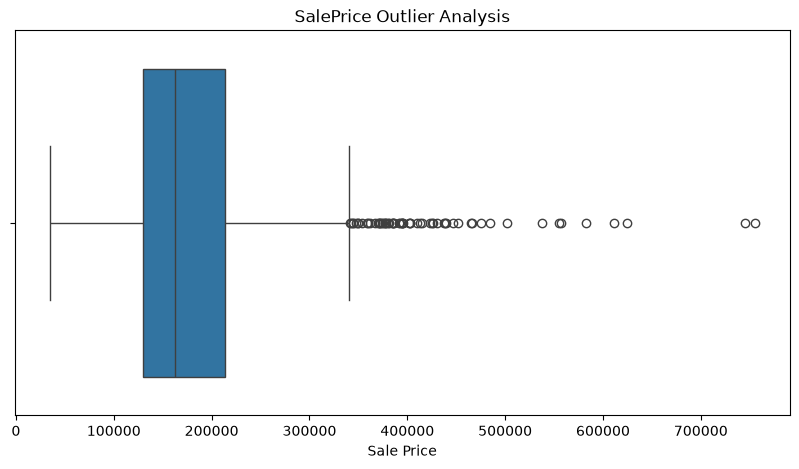

In [23]:
# Detecting outliers in SalePrice-----(Method 1)

plt.figure(figsize=(10, 5))

sns.boxplot(x=train_clean["SalePrice"])

plt.title("SalePrice Outlier Analysis")

plt.xlabel("Sale Price")

plt.show()

In [24]:
# IQR method for SalePrice------(Method 2)

Q1 = train_clean["SalePrice"].quantile(0.25)

Q3 = train_clean["SalePrice"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 129975.0
Q3: 214000.0
IQR: 84025.0
Lower Limit: 3937.5
Upper Limit: 340037.5


In [25]:
# Identifying potential outliers

saleprice_outliers = train_clean[
    (train_clean["SalePrice"] < lower_limit) |
    (train_clean["SalePrice"] > upper_limit)
]

print("Potential Outliers:", len(saleprice_outliers))

Potential Outliers: 61


In [26]:
# (Outlier chi mahiti pahanya sati)

saleprice_outliers[
    ["Id", "Neighborhood", "GrLivArea", "OverallQual", "SalePrice"]
].sort_values(
    by="SalePrice",
    ascending=False
)

,Id,Neighborhood,GrLivArea,OverallQual,SalePrice
691,692,NoRidge,4316,10,755000
1182,1183,NoRidge,4476,10,745000
1169,1170,NoRidge,3627,10,625000
898,899,NridgHt,2364,9,611657
803,804,NridgHt,2822,9,582933
...,...,...,...,...,...
990,991,NoRidge,2392,8,348000
642,643,NAmes,2704,8,345000
11,12,NridgHt,2324,9,345000
320,321,NridgHt,2596,9,342643


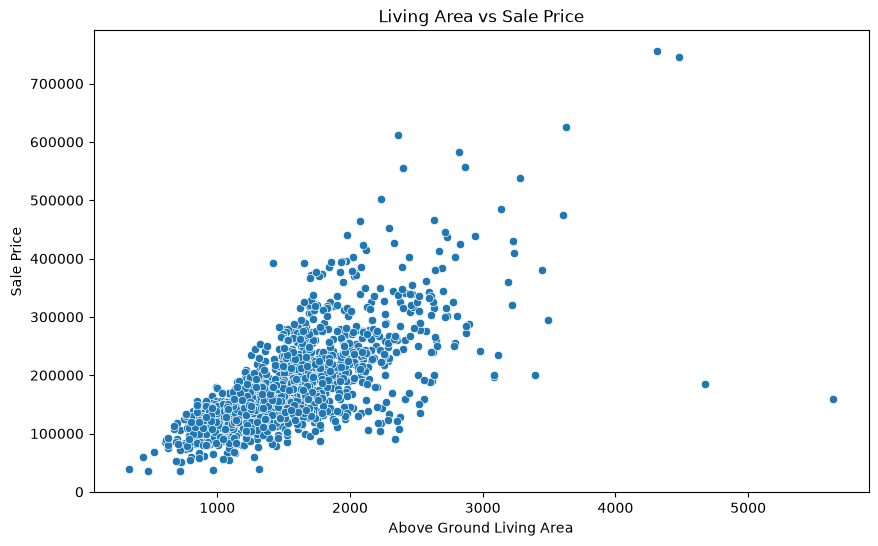

In [27]:
# Relationship between living area and sale price--------(Method 3 — Scatter Plot)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=train_clean,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Living Area vs Sale Price")

plt.xlabel("Above Ground Living Area")

plt.ylabel("Sale Price")

plt.show()

In [28]:
# Checking construction year validity

invalid_years = train_clean[
    train_clean["YearBuilt"] > train_clean["YrSold"]
]

print("Invalid Construction Years:", len(invalid_years))

Invalid Construction Years: 0


In [29]:
# Checking negative property areas

area_columns = [
    "LotArea",
    "TotalBsmtSF",
    "GrLivArea",
    "GarageArea"
]

for col in area_columns:

    negative_count = (train_clean[col] < 0).sum()

    print(col, "Negative Values:", negative_count)

LotArea Negative Values: 0
TotalBsmtSF Negative Values: 0
GrLivArea Negative Values: 0
GarageArea Negative Values: 0


In [30]:
# Saving cleaned datasets for exploratory analysis

train_clean.to_csv(
    "../data/processed/train_clean_for_eda.csv",
    index=False
)

test_clean.to_csv(
    "../data/processed/test_clean_for_eda.csv",
    index=False
)

print("Cleaned EDA datasets saved successfully!")

Cleaned EDA datasets saved successfully!


In [31]:
# Checking remaining missing values

remaining_train = train_clean.isnull().sum()
remaining_test = test_clean.isnull().sum()

print("Training Missing Columns:")
print(remaining_train[remaining_train > 0])

print("\nTesting Missing Columns:")
print(remaining_test[remaining_test > 0])

Training Missing Columns:
Series([], dtype: int64)

Testing Missing Columns:
MSZoning       4
Utilities      2
Exterior1st    1
Exterior2nd    1
KitchenQual    1
Functional     2
SaleType       1
dtype: int64


In [32]:
# Additional categorical columns

mode_columns = [
    "MSZoning",
    "Utilities",
    "Exterior1st",
    "Exterior2nd",
    "KitchenQual",
    "SaleType"
]

for col in mode_columns:

    mode_value = train_clean[col].mode()[0]

    train_clean[col] = train_clean[col].fillna(mode_value)

    test_clean[col] = test_clean[col].fillna(mode_value)

In [33]:
train_clean["Functional"] = train_clean[
    "Functional"
].fillna("Typ")

test_clean["Functional"] = test_clean[
    "Functional"
].fillna("Typ")

In [34]:
print("Training Missing Values:",
      train_clean.isnull().sum().sum())

print("Testing Missing Values:",
      test_clean.isnull().sum().sum())

Training Missing Values: 0
Testing Missing Values: 0


In [35]:
# Creating data cleaning summary

cleaning_summary = pd.DataFrame({
    "Metric": [
        "Original Training Rows",
        "Original Training Columns",
        "Cleaned Training Rows",
        "Cleaned Training Columns",
        "Remaining Training Missing Values",
        "Remaining Testing Missing Values",
        "Training Duplicate Rows",
        "Testing Duplicate Rows"
    ],

    "Value": [
        train_df.shape[0],
        train_df.shape[1],
        train_clean.shape[0],
        train_clean.shape[1],
        train_clean.isnull().sum().sum(),
        test_clean.isnull().sum().sum(),
        train_clean.duplicated().sum(),
        test_clean.duplicated().sum()
    ]
})

cleaning_summary

,Metric,Value
0,Original Training Rows,1460
1,Original Training Columns,81
2,Cleaned Training Rows,1460
3,Cleaned Training Columns,81
4,Remaining Training Missing Values,0
5,Remaining Testing Missing Values,0
6,Training Duplicate Rows,0
7,Testing Duplicate Rows,0


# Data Cleaning Summary

## Objective
To improve data quality and prepare the housing dataset for further analysis.

## Data Cleaning Activities

1. Created separate working copies of training and testing datasets.
2. Identified missing values in numerical and categorical columns.
3. Handled structural missing values based on property characteristics.
4. Used appropriate imputation strategies for remaining missing values.
5. Checked duplicate records and property IDs.
6. Validated numerical and categorical data types.
7. Identified potential outliers using Boxplots and the IQR method.
8. Performed basic business rule validation.
9. Saved cleaned exploratory datasets separately from the original raw data.

## Important Data Quality Considerations

- Missing values do not always represent incorrect data.
- Missing property features were handled according to their business meaning.
- Potential outliers were investigated rather than automatically deleted.
- Original raw datasets were preserved.
- Final machine learning preprocessing will be performed using pipelines after splitting the training data to prevent data leakage.

## Conclusion

The initial data cleaning and quality assessment process has been completed. The prepared datasets will be used for exploratory analysis, while final model preprocessing will be handled separately.